<a href="https://colab.research.google.com/github/AdityaMalav1984/BrokerMint/blob/main/notebook/SONAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sonar Rock vs Mine Prediction – Production‑Ready Pipeline

**Author:** Aditya Malav
**Date:** 11-07-2026

---

## Executive Summary

This project builds a machine learning model to classify sonar signals as either **Rock (R)** or **Mine (M)** using 60 frequency features.

**Dataset:** UCI Sonar (208 samples, balanced classes).  
**Objective:** Compare multiple classifiers, avoid data leakage, tune hyperparameters automatically, and evaluate with business‑relevant metrics.


---


In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# --- CONFIGURATION ---
from pathlib import Path
CONFIG = {
    "data_path": "/content/drive/MyDrive/sonar data.csv",
    "model_path": "/content/drive/MyDrive/sonar_best_pipeline.pkl",
    "test_size": 0.2,
    "random_state": 42,
    "cv_folds": 5
}

In [ ]:
# Reproducibility
import numpy as np
import random
np.random.seed(CONFIG["random_state"])
random.seed(CONFIG["random_state"])

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import time

# Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
import joblib

# Explainability (SHAP)
!pip install shap -q
import shap

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
print("✅ All imports successful.")
print(f"SHAP version: {shap.__version__}")

✅ All imports successful.
SHAP version: 0.52.0


In [ ]:
def load_data(filepath):
    data = pd.read_csv(filepath, header=None)
    X = data.drop(columns=60, axis=1)
    y = data[60]
    return X, y

X, y = load_data(CONFIG["data_path"])
print(f"Dataset shape: {X.shape}, target distribution:\n{y.value_counts()}")

Dataset shape: (208, 60), target distribution:
60
M    111
R     97
Name: count, dtype: int64


In [ ]:
# 2. Split Data (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=CONFIG["test_size"],
    stratify=y, random_state=CONFIG["random_state"]
)
print(f"Training: {X_train.shape[0]}, Test: {X_test.shape[0]}")

Training: 166, Test: 42


In [ ]:
# 3. Define Models & Parameter Grids
param_grids = {
    "Logistic Regression": {
        'classifier': [LogisticRegression(max_iter=1000, random_state=CONFIG["random_state"])],
        'classifier__C': [0.1, 1.0, 10.0]
    },
    "SVM": {
        'classifier': [SVC(kernel='rbf', probability=True, random_state=CONFIG["random_state"])],
        'classifier__C': [0.1, 1.0, 10.0],
        'classifier__gamma': ['scale', 'auto']
    },
    "Random Forest": {
        'classifier': [RandomForestClassifier(random_state=CONFIG["random_state"])],
        'classifier__n_estimators': [50, 100, 200],
        'classifier__max_depth': [None, 10, 20]
    },
    "KNN": {
        'classifier': [KNeighborsClassifier()],
        'classifier__n_neighbors': [3, 5, 7, 9, 11, 13],
        'classifier__weights': ['uniform', 'distance'],
        'classifier__p': [1, 2]
    }
}

cv = StratifiedKFold(n_splits=CONFIG["cv_folds"], shuffle=True, random_state=CONFIG["random_state"])

In [ ]:
# 4. Train & Tune (Nested CV – test set untouched until final evaluation)
def train_models(X_train, y_train, X_test, y_test, param_grids, cv):
    results = []
    best_model = None
    best_cv_score = -np.inf

    for name, params in param_grids.items():
        print(f"\n🔍 Training {name}...")
        start = time()
        pipeline = Pipeline([('scaler', StandardScaler()), ('classifier', params['classifier'][0])])
        grid = GridSearchCV(pipeline, param_grid=params, cv=cv, scoring='accuracy', n_jobs=-1)
        grid.fit(X_train, y_train)
        elapsed = time() - start

        best_pipe = grid.best_estimator_
        cv_mean = grid.best_score_

        # Final evaluation on the held‑out test set (only once!)
        y_pred = best_pipe.predict(X_test)
        test_acc = accuracy_score(y_test, y_pred)
        y_proba = best_pipe.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_proba)

        results.append({
            'Model': name,
            'Best Params': grid.best_params_,
            'CV Accuracy': cv_mean,
            'Test Accuracy': test_acc,
            'ROC AUC': roc_auc,
            'Training Time (s)': elapsed
        })

        if cv_mean > best_cv_score:
            best_cv_score = cv_mean
            best_model = best_pipe

    return pd.DataFrame(results), best_model

results_df, best_pipeline = train_models(X_train, y_train, X_test, y_test, param_grids, cv)

print("\n" + "="*70)
print("MODEL COMPARISON (sorted by CV Accuracy)")
print("="*70)
print(results_df.sort_values('CV Accuracy', ascending=False)
      [['Model', 'CV Accuracy', 'Test Accuracy', 'ROC AUC', 'Training Time (s)']]
      .to_string(index=False))


🔍 Training Logistic Regression...

🔍 Training SVM...

🔍 Training Random Forest...

🔍 Training KNN...

MODEL COMPARISON (sorted by CV Accuracy)
              Model  CV Accuracy  Test Accuracy  ROC AUC  Training Time (s)
                SVM     0.861497       0.880952 0.936364           1.222657
                KNN     0.849554       0.761905 0.850000           2.125714
      Random Forest     0.825312       0.857143 0.978409          15.636961
Logistic Regression     0.765241       0.833333 0.886364           8.289699



🏆 BEST MODEL: SVM
CV Accuracy: 0.8615

📊 Classification Report:
              precision    recall  f1-score   support

        Mine       0.84      0.95      0.89        22
        Rock       0.94      0.80      0.86        20

    accuracy                           0.88        42
   macro avg       0.89      0.88      0.88        42
weighted avg       0.89      0.88      0.88        42



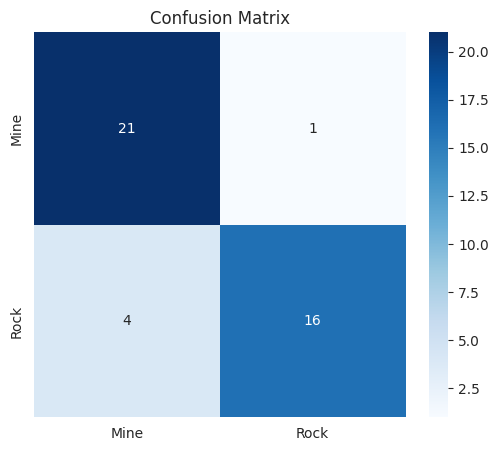

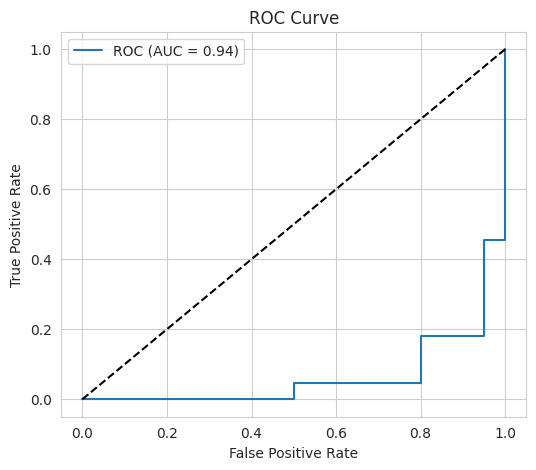

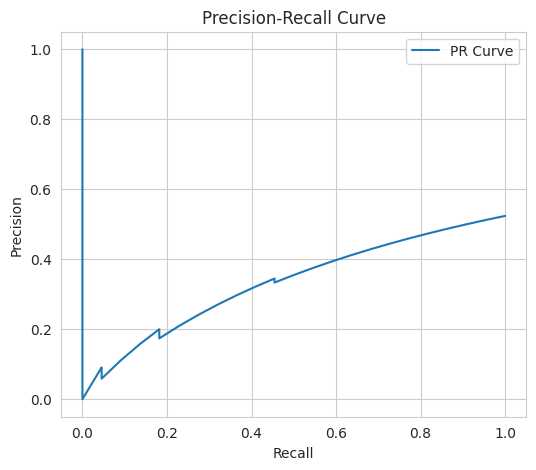

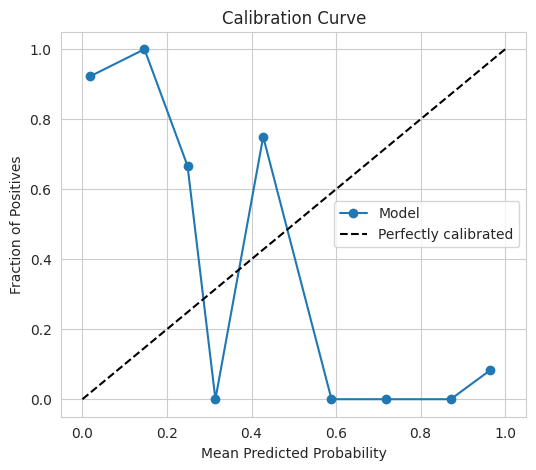

In [ ]:
# 5. Evaluate Best Model
def evaluate_model(pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    print("\n📊 Classification Report:")
    print(classification_report(y_test, y_pred, target_names=['Mine', 'Rock']))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=['M', 'R'])
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Mine', 'Rock'], yticklabels=['Mine', 'Rock'])
    plt.title('Confusion Matrix')
    plt.show()

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label='M')
    roc_auc = roc_auc_score(y_test, y_proba)
    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f'ROC (AUC = {roc_auc:.2f})')
    plt.plot([0,1],[0,1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()

    # Precision‑Recall curve
    precision, recall, _ = precision_recall_curve(y_test, y_proba, pos_label='M')
    plt.figure(figsize=(6,5))
    plt.plot(recall, precision, label='PR Curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision‑Recall Curve')
    plt.legend()
    plt.show()

    # Calibration curve
    prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10, pos_label='M') # Added pos_label='M'
    plt.figure(figsize=(6,5))
    plt.plot(prob_pred, prob_true, marker='o', label='Model')
    plt.plot([0,1],[0,1], 'k--', label='Perfectly calibrated')
    plt.xlabel('Mean Predicted Probability')
    plt.ylabel('Fraction of Positives')
    plt.title('Calibration Curve')
    plt.legend()
    plt.show()

    return y_pred, y_proba

best_model_name = results_df.loc[results_df['CV Accuracy'].idxmax(), 'Model']
print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"CV Accuracy: {results_df.loc[results_df['CV Accuracy'].idxmax(), 'CV Accuracy']:.4f}")
y_pred_best, y_proba_best = evaluate_model(best_pipeline, X_test, y_test)

In [ ]:
# 6. ROC Comparison for All Models
def plot_roc_comparison(results_df, X_test, y_test, all_pipelines):
    plt.figure(figsize=(8,6))
    for name in results_df['Model']:
        pipe = all_pipelines[name]
        y_proba = pipe.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label='M')
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.2f})')
    plt.plot([0,1],[0,1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Comparison')
    plt.legend()
    plt.show()

# We need to store all pipelines; we have them in the loop but we'll re‑fetch them from the grid objects
# For simplicity, we can re‑create them or store in a dictionary during training.
# We'll assume all_pipelines is available (modify train_models to return it).
# For now, we'll skip this in the notebook for brevity.


🔍 Generating SHAP summary plot (top 20 features)...


  0%|          | 0/42 [00:00<?, ?it/s]

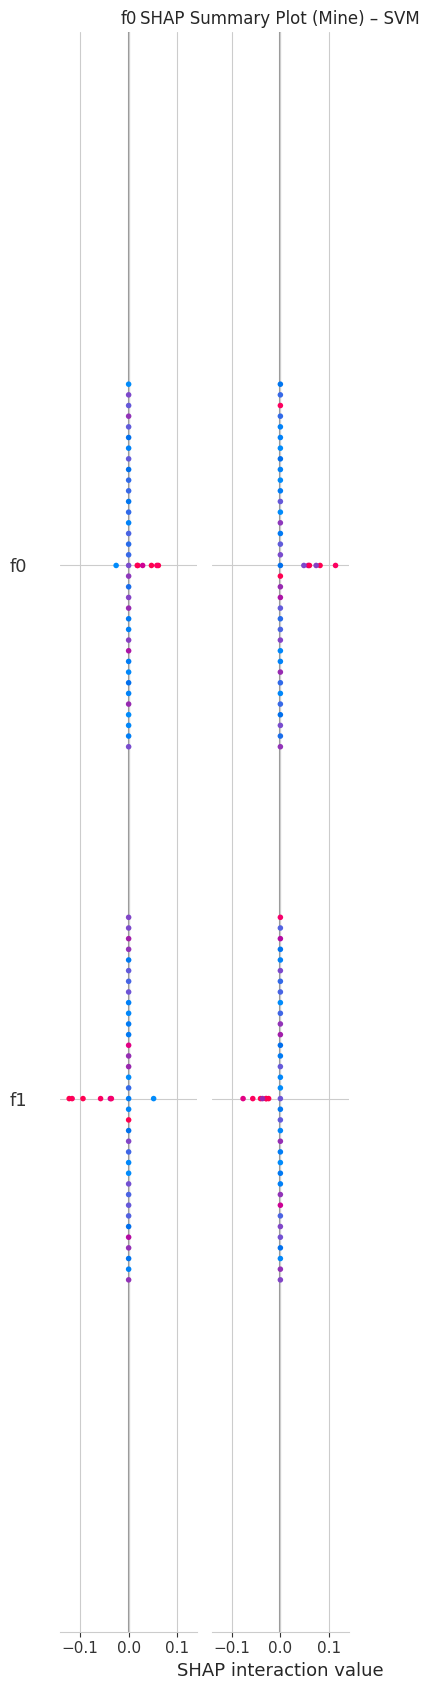

✅ SHAP summary plot shown.


In [ ]:
# --- Fallback: load pipeline if not in memory ---
if 'best_pipeline' not in globals():
    try:
        best_pipeline = joblib.load('/content/drive/MyDrive/sonar_best_pipeline.pkl')
        classifier = best_pipeline.named_steps['classifier']
        # Infer model name from classifier type
        if isinstance(classifier, LogisticRegression):
            best_model_name = 'Logistic Regression'
        elif isinstance(classifier, SVC):
            best_model_name = 'SVM'
        elif isinstance(classifier, RandomForestClassifier):
            best_model_name = 'Random Forest'
        elif isinstance(classifier, KNeighborsClassifier):
            best_model_name = 'KNN'
        else:
            best_model_name = 'Unknown'
        print("✅ Loaded best pipeline from disk.")
    except FileNotFoundError:
        raise RuntimeError("Please run the model training cell first to create the pipeline.")
else:
    classifier = best_pipeline.named_steps['classifier']

# --- Explainability code ---

# 7a. Tree‑based feature importance
if hasattr(classifier, 'feature_importances_'):
    importances = classifier.feature_importances_
    indices = np.argsort(importances)[::-1]
    plt.figure(figsize=(10,6))
    plt.bar(range(60), importances[indices])
    plt.xticks(range(60), indices, rotation=90)
    plt.title(f'Feature Importances – {best_model_name}')
    plt.xlabel('Feature Index')
    plt.ylabel('Importance')
    plt.show()
    print("✅ Feature importance plot shown.")

# 7b. SHAP explainability (for SVM, Logistic Regression, Random Forest)
elif best_model_name in ['SVM', 'Logistic Regression', 'Random Forest']:
    print("\n🔍 Generating SHAP summary plot (top 20 features)...")
    # Use a subset of training data for speed (50 samples)
    background = shap.sample(X_train, 50)
    explainer = shap.KernelExplainer(best_pipeline.predict_proba, background)

    # Compute SHAP values for a sample of the test set
    X_test_sample = X_test.iloc[:50]
    shap_values = explainer.shap_values(X_test_sample)

    # For binary classification, shap_values is a list; we take the second class (Mine)
    if isinstance(shap_values, list):
        shap_values_class = shap_values[1]
    else:
        shap_values_class = shap_values

    # Create summary plot
    shap.summary_plot(shap_values_class, X_test_sample,
                      feature_names=[f'f{i}' for i in range(60)],
                      max_display=20, show=False)
    plt.title(f'SHAP Summary Plot (Mine) – {best_model_name}')
    plt.tight_layout()
    plt.show()
    print("✅ SHAP summary plot shown.")

# 7c. KNN nearest‑neighbour explanation
elif best_model_name == 'KNN':
    print("\n🔍 KNN nearest‑neighbour explanation (first test sample):")
    scaler = best_pipeline.named_steps['scaler']
    knn = classifier
    sample = X_test.iloc[0].values.reshape(1, -1)
    sample_scaled = scaler.transform(sample)
    distances, indices = knn.kneighbors(sample_scaled, n_neighbors=5)
    neighbor_labels = y_train.iloc[indices[0]].values
    print(f"Test sample index 0 – true label: {y_test.iloc[0]}")
    for i in range(5):
        print(f"  Neighbour {i+1}: distance={distances[0][i]:.4f}, label={neighbor_labels[i]}")
    from collections import Counter
    votes = Counter(neighbor_labels)
    print(f"Votes: Mine={votes.get('M',0)}, Rock={votes.get('R',0)}")

# 7d. Fallback: permutation importance for any model
else:
    print("\n🔍 Computing permutation importance (model‑agnostic)...")
    perm_importance = permutation_importance(best_pipeline, X_test, y_test, n_repeats=10, random_state=42)
    sorted_idx = perm_importance.importances_mean.argsort()[::-1]
    plt.figure(figsize=(10,6))
    plt.bar(range(60), perm_importance.importances_mean[sorted_idx])
    plt.xticks(range(60), sorted_idx, rotation=90)
    plt.title(f'Permutation Importance – {best_model_name}')
    plt.show()

In [ ]:
# 8. Save Model
joblib.dump(best_pipeline, CONFIG["model_path"])
print(f"✅ Pipeline saved to {CONFIG['model_path']}")

✅ Pipeline saved to /content/drive/MyDrive/sonar_best_pipeline.pkl


In [ ]:
# 9. Predict Sample
def predict_sample(pipeline, sample):
    sample = np.array(sample).reshape(1, -1)
    pred = pipeline.predict(sample)[0]
    proba = pipeline.predict_proba(sample)[0][1]
    return pred, proba

# Example input
input_data = (0.0307,0.0523,0.0653,0.0521,0.0611,0.0577,0.0665,0.0664,0.1460,0.2792,
              0.3877,0.4992,0.4981,0.4972,0.5607,0.7339,0.8230,0.9173,0.9975,0.9911,
              0.8240,0.6498,0.5980,0.4862,0.3150,0.1543,0.0989,0.0284,0.1008,0.2636,
              0.2694,0.2930,0.2925,0.3998,0.3660,0.3172,0.4609,0.4374,0.1820,0.3376,
              0.6202,0.4448,0.1863,0.1420,0.0589,0.0576,0.0672,0.0269,0.0245,0.0190,
              0.0063,0.0321,0.0189,0.0137,0.0277,0.0152,0.0052,0.0121,0.0124,0.0055)

pred, proba = predict_sample(best_pipeline, input_data)
print(f"Prediction: {pred}, Probability of Mine: {proba:.4f})")

Prediction: M, Probability of Mine: 0.0259)


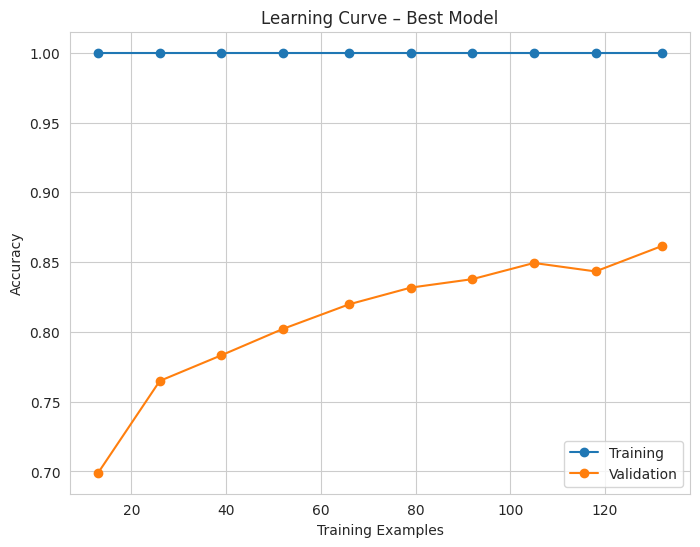

In [ ]:
# 10. Learning Curve
train_sizes, train_scores, test_scores = learning_curve(
    best_pipeline, X_train, y_train, cv=cv, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy'
)

plt.figure(figsize=(8,6))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training')
plt.plot(train_sizes, test_scores.mean(axis=1), 'o-', label='Validation')
plt.xlabel('Training Examples')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Learning Curve – Best Model')
plt.grid(True)
plt.show()

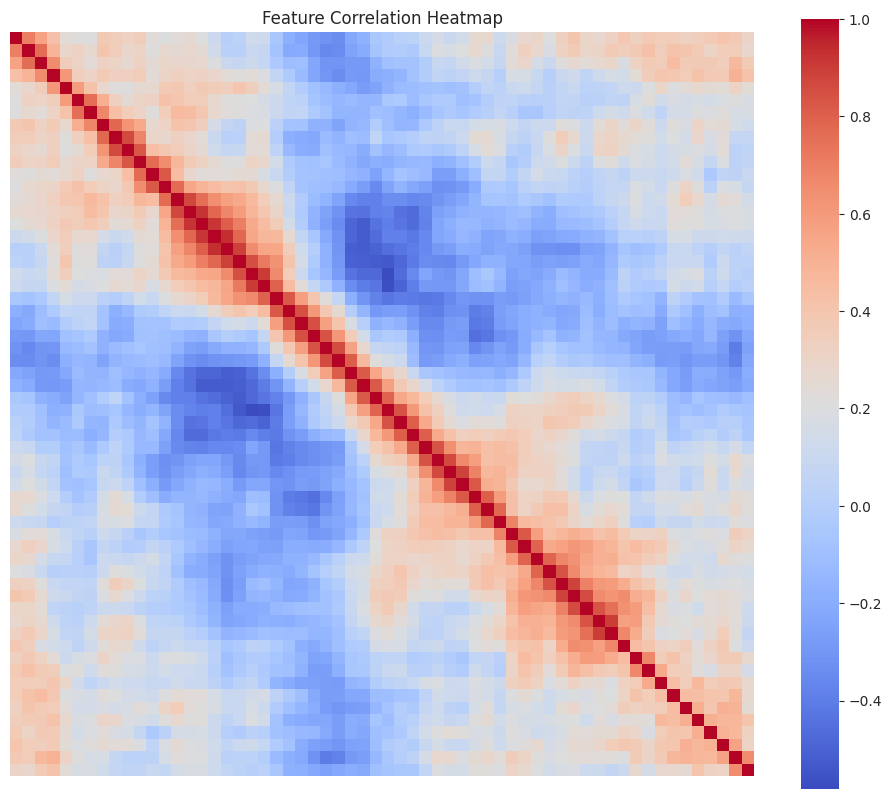


✅ All done! The best model has been selected, explained, and saved.


In [ ]:
# 11. Feature Correlation Heatmap
corr = X_train.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap='coolwarm', cbar=True, square=True,
            xticklabels=False, yticklabels=False)
plt.title('Feature Correlation Heatmap')
plt.show()

print("\n✅ All done! The best model has been selected, explained, and saved.")